# Part 1 — Embeddings: turning tokens into vectors that mean something

⏱ **~2 hours** · 📁 everything happens in this notebook · 📺 CME295 Lecture 1, *"Token representation"* / word2vec section

**After this notebook you can explain:**
- what an embedding layer *is* mathematically (it's a lookup table, and it's also a matrix multiplication)
- why one-hot vectors are a bad representation
- where meaning comes from (the distributional hypothesis) and how word2vec learns it
- why we compare embeddings with cosine similarity
- why `king − man + woman ≈ queen`
- **static vs. contextual** embeddings, and why that difference leads to attention

In [1]:
# Setup: run this cell first.
%load_ext autoreload
%autoreload 2
import sys, pathlib
root = pathlib.Path.cwd()
while not (root / "minitf").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import math, random
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from minitf import check, viz, corpus
torch.manual_seed(0);

## 1. To a model, tokens are just IDs

A neural network can't read text. We split text into **tokens** and give each token an integer **ID** from a vocabulary.
How you split the text (whole words, characters, or **subwords** with BPE, the Sennrich et al. paper in your folder) is called **tokenization**. In this notebook tokens are words. In Part 5 they are characters.

In [2]:
words = ["the", "king", "queen", "man", "woman", "apple"]
stoi = {w: i for i, w in enumerate(words)}
ids = torch.tensor([stoi[w] for w in "the king the queen".split()])
print(ids)   # this list of integers is all the model ever receives

tensor([0, 1, 0, 2])


## 2. First attempt: one-hot vectors

Give each token a vector of length V (the vocabulary size) that is all zeros except a single 1 at its ID.

In [3]:
V = len(words)
one_hot = F.one_hot(torch.arange(V), V).float()
print(one_hot)
print("cos(king, queen) =", F.cosine_similarity(one_hot[1], one_hot[2], dim=0).item())
print("cos(king, apple) =", F.cosine_similarity(one_hot[1], one_hot[5], dim=0).item())

tensor([[1., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 1., 0., 0.],
        [0., 0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 0., 1.]])
cos(king, queen) = 0.0
cos(king, apple) = 0.0


Two problems:
1. **No notion of similarity.** Every pair of different words is exactly as different as any other pair (cosine 0). *King* is as far from *queen* as from *apple*.
2. **Huge and sparse.** Real vocabularies have 30k–200k tokens, so each vector would have that many numbers, almost all zero.

## 3. Embeddings: a learnable lookup table

An **embedding matrix** $E$ has one row per token: shape `(V, d)`, where `d` is small (64 to 12,288 in real models).
**The embedding of token *i* is row *i*.** These numbers start random and are learned by gradient descent.

🔑 **Interview favourite:** looking up row *i* gives *exactly* the same result as multiplying a one-hot vector by $E$:

$$\text{onehot}(i)^\top E = E[i]$$

So an embedding layer **is** a linear layer (with no bias) applied to one-hot inputs. `nn.Embedding` just skips multiplying by all those zeros.

### ✍️ Your turn: show all three are the same
Compute the embeddings of `ids` three ways:
- `via_lookup`: index the rows of `E` directly
- `via_onehot`: `F.one_hot(ids, V).float() @ E`
- `via_module`: call `emb(ids)` (its weights are already a copy of `E`)

In [4]:
torch.manual_seed(0);
V, d = 6, 4
E = torch.randn(V, d)
emb = nn.Embedding(V, d)
emb.weight.data = E.clone()
ids = torch.tensor([1, 2, 1])
via_lookup = E[ids]
via_onehot = F.one_hot(ids, V).float() @ E
via_module = emb(ids)

In [5]:
check.close("via_lookup", via_lookup, E[[1, 2, 1]])
check.close("via_onehot == via_lookup", via_onehot, via_lookup)
check.close("via_module == via_lookup", via_module, via_lookup)

✅ via_lookup is correct
✅ via_onehot == via_lookup is correct
✅ via_module == via_lookup is correct


### Which rows get gradients?
Only the rows that were actually **used** get a gradient. This is why rare words learn slowly: their row is rarely updated.

In [6]:
emb.weight.grad = None
loss = emb(ids).sum()
loss.backward()
print(emb.weight.grad)

tensor([[0., 0., 0., 0.],
        [2., 2., 2., 2.],
        [1., 1., 1., 1.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


<details><summary>🤔 Why is row 1 all 2s, row 2 all 1s, and every other row 0? Think, then click.</summary>

Token 1 appears **twice** in `ids = [1, 2, 1]`, so its gradient is added twice. Token 2 appears once. The other tokens weren't used, so the loss doesn't depend on their rows at all.
</details>

## 4. Measuring similarity: cosine

$$\cos(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|} \in [-1, 1]$$

1 means same direction, 0 means unrelated (orthogonal), −1 means opposite.
**Why not the plain dot product?** A dot product also grows with vector **length**, and length often tracks word frequency, not meaning. Cosine compares **direction only**.
(Attention *does* use the raw, scaled dot product. There, length carries useful information, and the model learns to control it through $W^Q$ and $W^K$.)

### ✍️ Your turn
`cosine_to_all(vec, E)`: cosine similarity between one vector `vec` of shape `(d,)` and **every row** of `E` of shape `(N, d)`, returned with shape `(N,)`. No loops.

*Hint:* divide each row of `E` by its length, `E / E.norm(dim=-1, keepdim=True)`, do the same for `vec`, then use one matrix-vector product.

In [7]:
def cosine_to_all(vec, E):
    E_unit = E / E.norm(dim=-1, keepdim=True)
    v_unit = vec / vec.norm()
    return E_unit @ v_unit

In [8]:
E_test, v_test = torch.randn(10, 5), torch.randn(5)
check.close("cosine_to_all", cosine_to_all(v_test, E_test), F.cosine_similarity(E_test, v_test[None, :], dim=-1))

✅ cosine_to_all is correct


## 5. Where does meaning come from? The distributional hypothesis

> *"You shall know a word by the company it keeps."* (J.R. Firth, 1957)

Words that appear in **similar contexts** have **similar meanings**. **word2vec** (Mikolov et al., 2013) turns this into a training task: **from a word, predict the words around it** (the *skip-gram* variant). To do this well, words with similar contexts are pushed toward similar vectors.

We'll train it on a **synthetic corpus**, where we know the hidden truth. There are 8 people, and each has 3 hidden attributes:

| | gender | status | age |
|---|---|---|---|
| king / queen | male / female | royal | adult |
| prince / princess | male / female | royal | young |
| man / woman | male / female | common | adult |
| boy / girl | male / female | common | young |

Each sentence shows **one** attribute through its context words (*"he"*, *"throne"*, *"school"*, ...). There are also animals and foods.
**The model is never told any of this.** Let's see whether it figures it out.

In [9]:
sentences = corpus.generate(n_sentences=30000, seed=0)
itos, stoi = corpus.build_vocab(sentences)
V = len(itos)
print(f"{len(sentences)} sentences, {sum(map(len, sentences))} words, vocabulary of {V}")
for s in random.Random(1).sample(sentences, 10):
    print("  ", " ".join(s))

30000 sentences, 166344 words, vocabulary of 110
   the king sat on the throne
   the boy lives in the village
   the princess walked with the sheep
   the woman works on the farm
   we ate the bread for lunch
   the girl plays with toys
   the king ate the bread
   the bread came out of the oven
   the woman lost her hat
   the prince walked with the horse


## 6. Making skip-gram training pairs

For every position `i` in a sentence, and every other position `j` at most `window` words away, make the pair **(center = word i, context = word j)**. Pairs never cross from one sentence into the next.

```
sentence: the  king  sat  on  the  throne       window = 2
center "sat" -> contexts: "the", "king", "on", "the"
```

### ✍️ Your turn
`make_skipgram_pairs(ids, window)` takes **one** sentence as a list of IDs and returns a list of `(center, context)` tuples.

In [10]:
def make_skipgram_pairs(ids, window):
    pairs = []
    for i in range(len(ids)):
        for j in range(max(0, i - window), min(len(ids), i + window + 1)):
            if j != i:
                pairs.append((ids[i], ids[j]))
    return pairs

In [11]:
got = make_skipgram_pairs([10, 11, 12, 13], window=1)
check.equal("pairs for [10, 11, 12, 13], window=1", sorted(got),
            sorted([(10, 11), (11, 10), (11, 12), (12, 11), (12, 13), (13, 12)]))
check.equal("number of pairs with window=2", len(make_skipgram_pairs([1, 2, 3, 4, 5], 2)), 14)

✅ pairs for [10, 11, 12, 13], window=1 = [(10, 11), (11, 10), (11, 12), (12, 11), (12, 13), (13, 12)]
✅ number of pairs with window=2 = 14


In [12]:
WINDOW = 2
pairs = torch.tensor([p for s in sentences for p in make_skipgram_pairs([stoi[w] for w in s], WINDOW)])
print("training pairs:", pairs.shape)
print("examples:", [(itos[c], itos[x]) for c, x in pairs[:6].tolist()])

training pairs:

 torch.Size([485376, 2])
examples: [('we', 'ate'), ('we', 'the'), ('ate', 'we'), ('ate', 'the'), ('ate', 'bread'), ('the', 'we')]


## 7. The skip-gram model

It's tiny:

```
center id ──► embedding lookup E (V, d) ──► Linear to V scores ──► softmax = P(context word | center word)
```
The loss is cross-entropy against the context word we actually saw. The **embedding matrix** is what we keep at the end.

> 💡 **Negative sampling.** Real word2vec has a vocabulary of ~1M words, and a softmax over 1M classes for every pair is too slow. So it changes the question from *"which of the 1M words is the context?"* to *"is this (word, context) pair real or a random fake?"*: a yes/no classifier with ~5 random "negative" words per pair. Our vocabulary has ~110 words, so a plain softmax is fine and simpler.

### ✍️ Your turn
- `__init__`: `self.embed = nn.Embedding(V, d)` and `self.out = nn.Linear(d, V, bias=False)`
- `forward(center_ids)`: `(N,)` IDs → `(N, V)` logits

In [13]:
class SkipGram(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.embed = nn.Embedding(V, d)
        self.out = nn.Linear(d, V, bias=False)

    def forward(self, center_ids):
        return self.out(self.embed(center_ids))

In [14]:
torch.manual_seed(0);
model = SkipGram(V, d=16)
check.shape("SkipGram output", model(torch.tensor([0, 1, 2])), (3, V))

✅ SkipGram output: shape (3, 110)


Before training, the embeddings are random, so the "nearest neighbours" are noise:

In [15]:
def most_similar(word, E, k=5):
    sims = cosine_to_all(E[stoi[word]], E)
    sims[stoi[word]] = -2                       # don't return the word itself
    top = sims.topk(k)
    return [(itos[i], round(s, 2)) for s, i in zip(top.values.tolist(), top.indices.tolist())]

print("king ->", most_similar("king", model.embed.weight.detach()))

king -> [('at', 0.73), ('for', 0.65), ('delicious', 0.57), ('kingdom', 0.57), ('dog', 0.56)]


## 8. Train it

### ✍️ Your turn: the training loop
3 epochs; in each epoch, shuffle the pairs and go through them in batches of 512. Inside a batch: the 5 lines from Part 0. The center word is column 0 of `batch` and the context is column 1.

epoch 0: loss 2.458


epoch 1: loss 2.421


epoch 2: loss 2.428


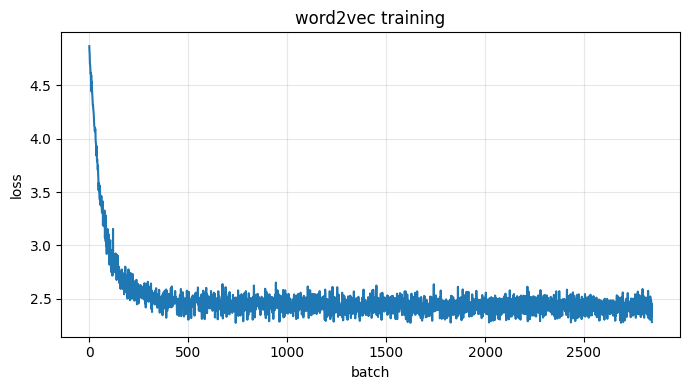

In [16]:
torch.manual_seed(0);
model = SkipGram(V, d=16)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
losses = []
for epoch in range(3):
    perm = torch.randperm(len(pairs))
    for start in range(0, len(pairs), 512):
        batch = pairs[perm[start:start + 512]]
        logits = model(batch[:, 0])
        loss = F.cross_entropy(logits, batch[:, 1])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    print(f"epoch {epoch}: loss {sum(losses[-100:]) / 100:.3f}")
viz.plot_curves({"skip-gram loss": losses}, title="word2vec training", xlabel="batch")

<details><summary>🤔 Why doesn't the loss go to 0?</summary>

The task really is uncertain: after "king", the next word could be "sat", "said", "wore", "the", and so on. The best possible model predicts a *distribution* over contexts, and the cross-entropy of a spread-out distribution is above 0.
</details>

## 9. What did it learn?

In [17]:
E = model.embed.weight.detach()
for w in ["king", "queen", "boy", "dog", "apple", "bread"]:
    print(f"{w:>6} ->", most_similar(w, E))

  king -> [('queen', 0.85), ('man', 0.74), ('prince', 0.67), ('woman', 0.66), ('princess', 0.59)]
 queen -> [('king', 0.85), ('woman', 0.82), ('princess', 0.78), ('man', 0.7), ('prince', 0.68)]
   boy -> [('man', 0.8), ('prince', 0.77), ('girl', 0.76), ('woman', 0.65), ('princess', 0.59)]
   dog -> [('cat', 0.88), ('sheep', 0.7), ('horse', 0.69), ('cow', 0.62), ('ball', 0.59)]
 apple -> [('cherry', 0.97), ('banana', 0.94), ('cake', 0.76), ('bread', 0.64), ('throne', 0.62)]
 bread -> [('cake', 0.83), ('banana', 0.72), ('cherry', 0.65), ('apple', 0.64), ('out', 0.53)]


### ✍️ Your turn: analogies
*"a is to b as c is to ?"* is answered by the word closest to $E[b] - E[a] + E[c]$. Leave out a, b and c themselves.

Why should this work? `king − man` cancels **gender** and **age** (both male adults) and leaves **royal − common**. Adding that to `woman` gives a *royal female adult*.

In [18]:
def analogy(a, b, c, E):
    """Returns the word w (not a, b or c) whose embedding is most cosine-similar to E[b] - E[a] + E[c]."""
    target = E[stoi[b]] - E[stoi[a]] + E[stoi[c]]
    sims = cosine_to_all(target, E)
    for w in (a, b, c):
        sims[stoi[w]] = -2
    return itos[sims.argmax().item()]

In [19]:
for a, b, c in [("man", "king", "woman"), ("boy", "prince", "girl"), ("man", "boy", "woman"),
                ("prince", "king", "princess"), ("dog", "cat", "cow")]:
    print(f"{a} : {b}  ::  {c} : {analogy(a, b, c, E)}")
check.equal("man : king :: woman : ?", analogy("man", "king", "woman", E), "queen")

man : king  ::  woman : queen
boy : prince  ::  girl : princess
man : boy  ::  woman : girl
prince : king  ::  princess : queen
dog : cat  ::  cow : horse
✅ man : king :: woman : ? = 'queen'


### Look at it
PCA squeezes the 16-D vectors down to the 2 directions where they vary the most. You should see a **royal ↔ common** direction and an **adult ↔ young** direction. **Gender** is there too, in a third direction that a 2-D picture can't show (the analogies above prove it's there).

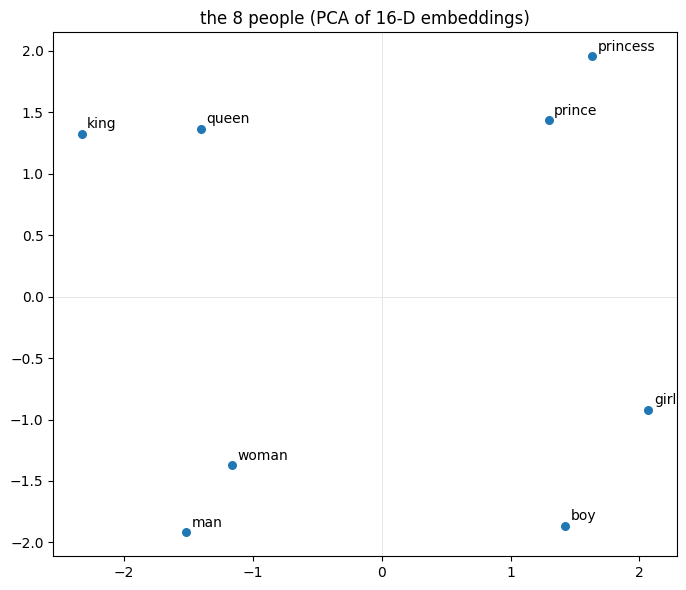

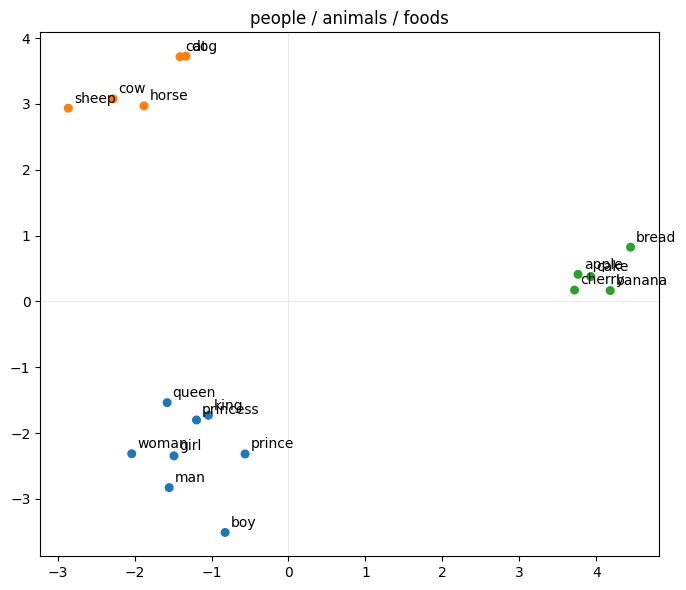

In [20]:
people = list(corpus.PEOPLE)
viz.plot_embeddings_2d(E[[stoi[w] for w in people]], people, title="the 8 people (PCA of 16-D embeddings)")

nouns = people + list(corpus.ANIMALS) + list(corpus.FOODS)
colors = [{"person": "tab:blue", "animal": "tab:orange", "food": "tab:green"}[corpus.category_of(w)] for w in nouns]
viz.plot_embeddings_2d(E[[stoi[w] for w in nouns]], nouns, colors=colors, title="people / animals / foods")

🎉 Nobody told the model what "royal" or "female" means. It found these directions **only from which words appear near which**.

## 10. The limit that leads to attention

word2vec gives each word **exactly one vector**, whatever its context:

- *"I sat by the river **bank**"* and *"I opened a **bank** account"*: the same vector for "bank".
- *"The **animal** didn't cross the street because **it** was tired"*: the vector for "it" knows nothing about the animal.

These are **static** embeddings. A Transformer starts the same way, with a lookup table, and then each **attention** layer lets every token pull in information from the tokens around it. The result is a **contextual** embedding: a different vector for every occurrence of a word. That's Part 2.

> In a Transformer the embedding table is **not** pre-trained with word2vec. It's an `nn.Embedding` initialised randomly and trained **end-to-end** with the rest of the model on the real task. You'll do exactly that in Part 4.

## ✅ Check your understanding

<details><summary>1. What is <code>nn.Embedding</code> mathematically?</summary>

A `(V, d)` matrix. The lookup `E[i]` equals `onehot(i) @ E`, so it's a bias-free linear layer on one-hot inputs, done as an indexing operation for speed.
</details>

<details><summary>2. Why not use one-hot vectors as the representation?</summary>

They're V-dimensional and sparse, and all pairs are orthogonal, so they hold no similarity at all. Nothing learned about one word carries over to a similar word.
</details>

<details><summary>3. How many parameters does an embedding table with V = 50,000 and d = 512 have?</summary>

50,000 × 512 = **25.6M**. Embedding tables are often a big share of a small model's parameters.
</details>

<details><summary>4. What is the distributional hypothesis, and how does skip-gram use it?</summary>

Words in similar contexts have similar meanings. Skip-gram trains each word's vector to predict its neighbours, so words with similar neighbours end up with similar vectors.
</details>

<details><summary>5. Why negative sampling?</summary>

A softmax over the whole vocabulary costs O(V) for every pair. Negative sampling replaces it with a yes/no task (real pair vs. k random words), which costs O(k).
</details>

<details><summary>6. Static vs. contextual embeddings?</summary>

Static (word2vec, GloVe): one vector per word type. Contextual (Transformer layer outputs, BERT): one vector per *occurrence*, which depends on the surrounding words. Attention is the mechanism that makes them contextual.
</details>

<details><summary>7. Why cosine similarity rather than the dot product for comparing word vectors?</summary>

The dot product mixes **direction** (meaning) with **length** (which often reflects frequency). Cosine normalises away the length.
</details>

**Next: `02_attention_by_hand.ipynb`**